<center><h1>Li_Sumi_HW7</h1></center>


Name: Li Sumi
<br>
Github Username: SumiLi-1
<br>
USC ID: 5751493481


## 1. Multi-class and Multi-Label Classification Using Support Vector Machines


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, hamming_loss, make_scorer, silhouette_score
from sklearn.cluster import KMeans
from imblearn.over_sampling import SMOTE


### (a) Load the Anuran Calls (MFCCs) Data Set


In [2]:
# Use the local data file; no download is needed.
data_path = 'data/Frogs_MFCCs.csv'
df = pd.read_csv(data_path)

label_columns = ['Family', 'Genus', 'Species']
# RecordID is only an identifier, so keep only MFCC columns as features.
feature_columns = [c for c in df.columns if c.startswith('MFCCs')]
X = df[feature_columns]
Y = df[label_columns]

# Fixed seed makes the 70/30 split reproducible.
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.70, random_state=42, stratify=Y['Species']
)

print('Data shape:', df.shape)
print('Training shape:', X_train.shape)
print('Test shape:', X_test.shape)
display(Y.nunique().rename('number of classes'))


Data shape: (7195, 26)
Training shape: (5036, 22)
Test shape: (2159, 22)


Family      4
Genus       8
Species    10
Name: number of classes, dtype: int64

### (b) Train a classifier for each label


#### (i) Evaluation metrics


In [3]:
# Exact match: all three labels are correct for a row.
# Hamming loss: fraction of individual labels that are incorrect.
# Hamming score: 1 - Hamming loss; larger is better.
def multilabel_scores(y_true, y_pred):
    # Exact match requires all three labels in a row to be correct.
    exact_match = np.mean(np.all(y_true.to_numpy() == y_pred.to_numpy(), axis=1))
    # Compare each cell directly because sklearn's hamming_loss does not support
    # string-valued multiclass-multioutput labels such as Family/Genus/Species.
    loss = np.mean(y_true.to_numpy() != y_pred.to_numpy())
    return pd.Series({
        'exact match': exact_match,
        'hamming score': 1 - loss,
        'hamming loss': loss
    })


def predict_three_models(models, X_new):
    # Put the three independent predictions back into a DataFrame.
    return pd.DataFrame(
        {label: models[label].predict(X_new) for label in label_columns},
        index=X_new.index
    )


#### (ii) Gaussian-kernel SVM for each label


In [4]:
# Train one explicit one-vs-rest RBF SVM for each of the three label columns.
# The grid uses 10-fold cross validation for both C and gamma.
rbf_grid = {
    'ovr__estimator__C': [0.1, 1, 10],
    'ovr__estimator__gamma': [0.01, 0.1, 1]
}
rbf_models = {}
rbf_best_parameters = {}

for label in label_columns:
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('ovr', OneVsRestClassifier(SVC(kernel='rbf')))
    ])
    search = GridSearchCV(pipe, rbf_grid, cv=10, scoring='accuracy', n_jobs=-1)
    search.fit(X_train, Y_train[label])
    rbf_models[label] = search.best_estimator_
    rbf_best_parameters[label] = search.best_params_

print('Best parameters for one-vs-rest RBF SVM:')
display(pd.DataFrame(rbf_best_parameters).T)

rbf_predictions = predict_three_models(rbf_models, X_test)
display(multilabel_scores(Y_test, rbf_predictions).to_frame('RBF SVM (OvR)'))


Best parameters for one-vs-rest RBF SVM:


,ovr__estimator__C,ovr__estimator__gamma
Family,10.0,0.1
Genus,10.0,0.1
Species,10.0,0.1


,RBF SVM (OvR)
exact match,0.986568
hamming score,0.990891
hamming loss,0.009109


#### (iii) L1-penalized linear SVM


In [5]:
# L1 penalty normally uses a linear kernel; scaling occurs inside each CV fold.
l1_grid = {'linearsvc__C': [0.01, 0.1, 1, 10]}
l1_models = {}
l1_best_parameters = {}

for label in label_columns:
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('linearsvc', LinearSVC(penalty='l1', dual=False, max_iter=10000))
    ])
    search = GridSearchCV(pipe, l1_grid, cv=10, scoring='accuracy', n_jobs=-1)
    search.fit(X_train, Y_train[label])
    l1_models[label] = search.best_estimator_
    l1_best_parameters[label] = search.best_params_

print('Best parameters for L1 SVM:')
display(pd.DataFrame(l1_best_parameters).T)

l1_predictions = predict_three_models(l1_models, X_test)
display(multilabel_scores(Y_test, l1_predictions).to_frame('L1 linear SVM'))


Best parameters for L1 SVM:


,linearsvc__C
Family,10
Genus,10
Species,10


,L1 linear SVM
exact match,0.917554
hamming score,0.949359
hamming loss,0.050641


#### (iv) L1 SVM with SMOTE for class imbalance


In [6]:
# SMOTE is inside the pipeline, so it is applied only to training folds.
from imblearn.pipeline import Pipeline as ImbPipeline

smote_models = {}
smote_best_parameters = {}

for label in label_columns:
    pipe = ImbPipeline([
        ('scale', StandardScaler()),
        ('smote', SMOTE(random_state=42, k_neighbors=3)),
        # LinearSVC uses one-vs-rest for multiclass classification by default.
        ('linearsvc', LinearSVC(penalty='l1', dual=False, max_iter=10000))
    ])
    search = GridSearchCV(pipe, l1_grid, cv=10, scoring='accuracy', n_jobs=-1)
    search.fit(X_train, Y_train[label])
    smote_models[label] = search.best_estimator_
    smote_best_parameters[label] = search.best_params_

print('Best parameters for SMOTE + L1 SVM:')
display(pd.DataFrame(smote_best_parameters).T)

smote_predictions = predict_three_models(smote_models, X_test)
comparison = pd.concat({
    'RBF SVM (OvR)': multilabel_scores(Y_test, rbf_predictions),
    'L1 linear SVM': multilabel_scores(Y_test, l1_predictions),
    'SMOTE + L1 SVM': multilabel_scores(Y_test, smote_predictions)
}, axis=1)
display(comparison)

# State a conclusion based on the actual test-set values instead of a fixed sentence.
best_exact = comparison.loc['exact match'].idxmax()
best_hamming = comparison.loc['hamming score'].idxmax()
smote_change = comparison.loc['hamming score', 'SMOTE + L1 SVM'] - comparison.loc['hamming score', 'L1 linear SVM']
direction = 'improved' if smote_change > 0 else 'did not improve'
print(f'Conclusion: {best_exact} has the highest exact match, and {best_hamming} has the highest Hamming score.')
print(f'Compared with L1 linear SVM, SMOTE {direction} Hamming score by {smote_change:.4f}.')


Best parameters for SMOTE + L1 SVM:


,linearsvc__C
Family,10
Genus,10
Species,1


,RBF SVM (OvR),L1 linear SVM,SMOTE + L1 SVM
exact match,0.986568,0.917554,0.861510
hamming score,0.990891,0.949359,0.930678
hamming loss,0.009109,0.050641,0.069322


Conclusion: RBF SVM (OvR) has the highest exact match, and RBF SVM (OvR) has the highest Hamming score.
Compared with L1 linear SVM, SMOTE did not improve Hamming score by -0.0187.


## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set


### (a) Choose k automatically with silhouette score


Selected k for this displayed run: 5


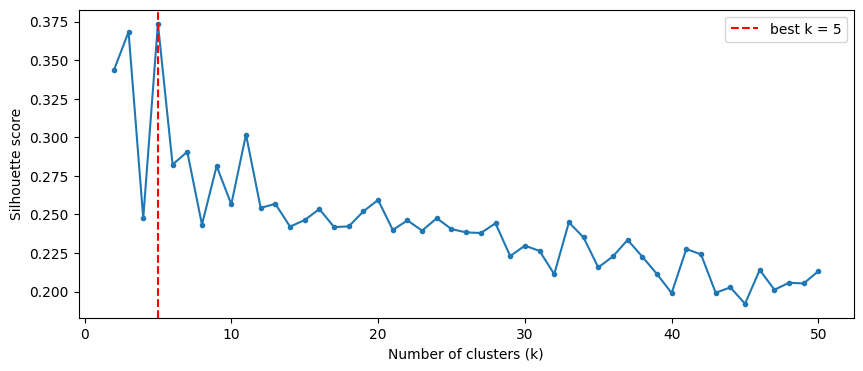

In [7]:
# Use the full data set for clustering and standardize all MFCC features.
X_all_scaled = StandardScaler().fit_transform(X)

def select_k_by_silhouette(X_values, random_state):
    # Select k automatically from 2,...,50 for one Monte-Carlo run.
    # A 1,000-row sample keeps silhouette scoring practical.
    scores = []
    for k in range(2, 51):
        km = KMeans(n_clusters=k, n_init=5, random_state=random_state)
        cluster_id = km.fit_predict(X_values)
        score = silhouette_score(X_values, cluster_id, sample_size=1000, random_state=random_state)
        scores.append(score)
    return np.argmax(scores) + 2, scores

# This first run shows the selected k and the silhouette plot.
best_k, silhouette_values = select_k_by_silhouette(X_all_scaled, random_state=42)
print('Selected k for this displayed run:', best_k)

plt.figure(figsize=(10, 4))
plt.plot(range(2, 51), silhouette_values, marker='o', markersize=3)
plt.axvline(best_k, color='red', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.legend()
plt.show()


### (b) Determine the majority Family, Genus, and Species in every cluster


In [8]:
def cluster_majority_labels(cluster_ids, true_labels):
    # For each cluster, choose the most frequent true label in each label column.
    result = pd.DataFrame({'cluster': cluster_ids}, index=true_labels.index)
    for label in label_columns:
        majority = result.join(true_labels[[label]]).groupby('cluster')[label].agg(lambda x: x.mode().iat[0])
        result[label] = result['cluster'].map(majority)
    return result


one_kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
one_cluster_ids = one_kmeans.fit_predict(X_all_scaled)
cluster_assignments = cluster_majority_labels(one_cluster_ids, Y)

print('Majority label triplet for each cluster:')
display(cluster_assignments.groupby('cluster')[label_columns].first())


Majority label triplet for each cluster:


,Family,Genus,Species
cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCinerascens
2,Leptodactylidae,Adenomera,AdenomeraAndre
3,Leptodactylidae,Adenomera,AdenomeraAndre
4,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) Monte-Carlo simulation: 50 Hamming distances


In [ ]:
# Repeat every clustering procedure 50 times. Each run reselects k automatically,
# fits K-Means, finds cluster-majority labels, and then calculates Hamming metrics.
hamming_distances = []
all_run_scores = []
selected_ks = []

for seed in range(50):
    selected_k, _ = select_k_by_silhouette(X_all_scaled, random_state=seed)
    km = KMeans(n_clusters=selected_k, n_init=5, random_state=seed)
    cluster_ids = km.fit_predict(X_all_scaled)
    assigned_labels = cluster_majority_labels(cluster_ids, Y)[label_columns]

    scores = multilabel_scores(Y, assigned_labels)
    hamming_distances.append(scores['hamming loss'])
    all_run_scores.append(scores)
    selected_ks.append(selected_k)

all_run_scores = pd.DataFrame(all_run_scores)
print(f'Average Hamming distance: {np.mean(hamming_distances):.4f}')
print(f'Standard deviation:       {np.std(hamming_distances, ddof=1):.4f}')
print('Selected k values across the 50 runs:')
display(pd.Series(selected_ks, name='k').value_counts().sort_index().to_frame('number of runs'))
display(all_run_scores.agg(['mean', 'std']))


## 3. ISLR 12.6.2


In [ ]:
# ISLR 12.6.2: Manual K-Means with K = 2.
# The six observations are (1,4), (1,3), (0,4), (5,1), (6,2), and (4,0).
# Parts (a)-(f): plot the observations; choose initial labels; compute centroids;
# reassign to the closest centroid; repeat until unchanged; then plot final clusters.

X_islr = np.array([
    [1, 4], [1, 3], [0, 4], [5, 1], [6, 2], [4, 0]
], dtype=float)
obs = np.arange(1, 7)

# (a) Plot observations and label them 1 through 6.
plt.figure(figsize=(5, 4))
plt.scatter(X_islr[:, 0], X_islr[:, 1], color='black')
for i, (x1, x2) in enumerate(X_islr):
    plt.text(x1 + 0.08, x2 + 0.08, str(obs[i]))
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('ISLR 12.6.2(a): Six observations')
plt.show()

# (b) Generate reproducible random labels. Repeat only if one cluster is empty.
rng = np.random.default_rng(42)
while True:
    initial_labels = rng.integers(1, 3, size=6)
    if len(np.unique(initial_labels)) == 2:
        break
print('Initial labels:', dict(zip(obs, initial_labels)))

# (c)-(e) Recompute centroids and labels until no observation changes cluster.
labels = initial_labels.copy()
iteration = 0
while True:
    iteration += 1
    centroids = np.array([X_islr[labels == k].mean(axis=0) for k in [1, 2]])
    distances = np.sqrt(((X_islr[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
    new_labels = distances.argmin(axis=1) + 1
    print(f'Iteration {iteration}: centroids = {centroids}; labels = {new_labels}')
    if np.array_equal(new_labels, labels):
        break
    labels = new_labels

# (f) Plot final clusters and their centroids.
final_centroids = np.array([X_islr[labels == k].mean(axis=0) for k in [1, 2]])
print('Final labels:', dict(zip(obs, labels)))
print('Final centroids:', final_centroids)

plt.figure(figsize=(5, 4))
for k, color in zip([1, 2], ['tab:blue', 'tab:orange']):
    points = X_islr[labels == k]
    plt.scatter(points[:, 0], points[:, 1], color=color, label=f'Cluster {k}', s=60)
plt.scatter(final_centroids[:, 0], final_centroids[:, 1], color='red', marker='X', s=150, label='Centroids')
for i, (x1, x2) in enumerate(X_islr):
    plt.text(x1 + 0.08, x2 + 0.08, str(obs[i]))
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('ISLR 12.6.2(f): Final K-Means clusters')
plt.legend()
plt.show()
